# Late-Delivery Predictor for an E-commerce Marketplace
**Field:** E-commerce · Operations  **Task:** Binary classification (imbalanced)  **Data:** Olist Brazilian E-Commerce (Kaggle, 9 tables)

**Notebook map**
1. Problem framing
2. Setup & data understanding
3. Building the target and joining the 9 tables
4. Train / test split (before anything is fitted)
5. EDA (univariate, bivariate, multivariate) and insights
6. Preprocessing pipeline
7. Baseline and model comparison (cross-validation)
8. Hyperparameter tuning
9. Threshold selection (business cost)
10. Final evaluation on the untouched test set and error analysis
11. Business insight and limitations
12. Export artifacts for the Streamlit app

> **How to run:** download the dataset from Kaggle, unzip the CSVs into `data/olist/`, then *Restart & Run All*. Total runtime is roughly 10–25 minutes, mostly the Random Forest search. Lower `N_ITER` in the config cell for a quick run.

## 1 · Problem framing

**Who has the problem?** The marketplace's operations / customer-experience team. A late delivery produces bad reviews, support tickets, and lost customers.

**Decision the model supports.** At the moment of purchase, score each order for late-delivery risk, then:
- warn the customer or reset expectations for high-risk orders,
- prioritise those orders with carriers,
- spot sellers and shipping lanes that are slowing down.

**Target.** `late = 1` if `order_delivered_customer_date > order_estimated_delivery_date`, else `0`. We build this label ourselves, using delivered orders only.

**Metric that matters.**
- Only about 1 in 12 orders is late, so **accuracy is misleading** (always predicting "on time" scores about 92%).
- A missed late order (false negative) costs more than an unnecessary warning (false positive). We therefore track **recall on the late class**, balanced against **precision**.
- We compare models with **PR-AUC** (average precision), which is threshold-free and honest under imbalance. We also report ROC-AUC.
- The operating **threshold** is chosen from an explicit cost ratio (`COST_FN` vs `COST_FP`) and not left at 0.5.

**No-leakage rule.** The model may only use information available **at purchase time**: purchase timestamp, the estimated delivery date shown at checkout, price, freight, product attributes, payment choice, and seller and customer location. Approval, carrier-pickup, and delivery timestamps and review scores are forbidden as features.

## 2 · Setup and data understanding

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (train_test_split, cross_validate, RandomizedSearchCV,
                                     StratifiedKFold, TimeSeriesSplit)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 4), "Needs scikit-learn >= 1.4 (TargetEncoder)"

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [2]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (train_test_split, cross_validate, RandomizedSearchCV,
                                     StratifiedKFold, TimeSeriesSplit)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 4), "Needs scikit-learn >= 1.4 (TargetEncoder)"

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [3]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (train_test_split, cross_validate, RandomizedSearchCV,
                                     StratifiedKFold, TimeSeriesSplit)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 4), "Needs scikit-learn >= 1.4 (TargetEncoder)"

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [4]:
from pathlib import Path
p = Path("data/olist")
print("Folder exists:", p.exists())
print("Contents:", [x.name for x in p.rglob("*")][:30] if p.exists() else "n/a")
print("Working directory:", Path.cwd())

Folder exists: True
Contents: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']
Working directory: E:\programming\دبلومة\دبلومة علوم الحاسب جامعة القاهرة\late-delivery-predictor


In [9]:
   from pathlib import Path
   DATA_DIR = Path(r"E:\programming\دبلومة\دبلومة علوم الحاسب جامعة القاهرة\late-delivery-predictor\data\olist")
   print(DATA_DIR, DATA_DIR.exists())

E:\programming\دبلومة\دبلومة علوم الحاسب جامعة القاهرة\late-delivery-predictor\data\olist True


In [10]:
FILES = {
    "orders":      "olist_orders_dataset.csv",
    "items":       "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "customers":   "olist_customers_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_tr": "product_category_name_translation.csv",
}
missing_files = [f for f in FILES.values() if not (DATA_DIR / f).exists()]
assert not missing_files, f"Missing in {DATA_DIR.resolve()}: {missing_files}"
raw = {k: pd.read_csv(DATA_DIR / f) for k, f in FILES.items()}

order_dates = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = raw["orders"]
for c in order_dates:
    orders[c] = pd.to_datetime(orders[c])
items, payments, reviews = raw["items"], raw["payments"], raw["reviews"]
customers, sellers, products = raw["customers"], raw["sellers"], raw["products"]
geolocation, category_tr = raw["geolocation"], raw["category_tr"]

overview = pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1],
                             "missing cells": int(v.isna().sum().sum())} for k, v in raw.items()}).T
overview

,rows,columns,missing cells
orders,99441,8,4908
items,112650,7,0
payments,103886,5,0
reviews,99224,7,145903
customers,99441,5,0
sellers,3095,4,0
products,32951,9,2448
geolocation,1000163,5,0
category_tr,71,2,0


In [11]:
# ───────────── CONFIG ─────────────
RANDOM_STATE = 42
DATA_DIR     = Path("data/olist")     # folder with the 9 Kaggle CSVs
APP_DATA_DIR = Path("data")           # small files shipped with the app (zip lookup, seller stats)
MODEL_DIR    = Path("model")

TIME_SPLIT = True    # True: train on earlier orders, test on the latest 20%.  False: stratified random split
TEST_FRAC  = 0.20
CV_SPLITS  = 4

# Business cost ratio used to choose the decision threshold:
# missing a late order is assumed 5x worse than an unnecessary warning / carrier escalation.
COST_FN, COST_FP = 5.0, 1.0

# Random-search budget per model (lower these for a quick run)
N_ITER = {"Logistic Regression": 3, "Random Forest": 2, "HistGradientBoosting": 5}
MODEL_DIR.mkdir(exist_ok=True); APP_DATA_DIR.mkdir(exist_ok=True)

# Optional: download straight from Kaggle (pip install kagglehub, needs Kaggle credentials)
# import kagglehub; DATA_DIR = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))

### Column dictionary (the columns we use)

| Table | Column | Meaning | Type |
|---|---|---|---|
| orders | `order_id`, `customer_id` | keys | id |
| orders | `order_status` | delivered / shipped / canceled … | categorical |
| orders | `order_purchase_timestamp` | time the order was placed | datetime |
| orders | `order_estimated_delivery_date` | delivery date promised at checkout | datetime |
| orders | `order_delivered_customer_date` | actual delivery date (**used only to build the label**) | datetime |
| order_items | `order_id`, `order_item_id`, `product_id`, `seller_id` | one row per item in an order | id |
| order_items | `price`, `freight_value` | item price and shipping cost (BRL) | numeric |
| products | `product_category_name` (Portuguese), `product_weight_g`, `product_length/height/width_cm` | product attributes | cat / numeric |
| category_tr | `product_category_name_english` | English category name | categorical |
| customers | `customer_zip_code_prefix`, `customer_state` | customer location | id / cat |
| sellers | `seller_zip_code_prefix`, `seller_state` | seller location | id / cat |
| geolocation | `geolocation_zip_code_prefix`, `lat`, `lng` | many GPS points per zip prefix | numeric |
| payments | `payment_type`, `payment_installments`, `payment_value` | how the customer paid | cat / numeric |
| reviews | `review_score` | 1–5 stars (**not used here**; reserved for the stretch model) | numeric |

Notes: the dataset has typos in some column names (e.g. `product_name_lenght`). Several tables are one-to-many (an order has many items, many payments), so we must aggregate to **one row per order** before modelling.

In [12]:
print("ORDERS: dtypes and missing values")
display(pd.DataFrame({"dtype": orders.dtypes.astype(str), "missing": orders.isna().sum(),
                      "missing %": (orders.isna().mean() * 100).round(2)}))
print("Order status counts:")
display(orders["order_status"].value_counts())
for name in ["products", "items", "payments", "customers", "sellers"]:
    m = raw[name].isna().sum()
    print(f"{name}: missing -> {dict(m[m > 0])}")

ORDERS: dtypes and missing values


,dtype,missing,missing %
order_id,str,0,0.0000
customer_id,str,0,0.0000
order_status,str,0,0.0000
order_purchase_timestamp,datetime64[us],0,0.0000
order_approved_at,datetime64[us],160,0.1600
order_delivered_carrier_date,datetime64[us],1783,1.7900
order_delivered_customer_date,datetime64[us],2965,2.9800
order_estimated_delivery_date,datetime64[us],0,0.0000


Order status counts:


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

products: missing -> {'product_category_name': np.int64(610), 'product_name_lenght': np.int64(610), 'product_description_lenght': np.int64(610), 'product_photos_qty': np.int64(610), 'product_weight_g': np.int64(2), 'product_length_cm': np.int64(2), 'product_height_cm': np.int64(2), 'product_width_cm': np.int64(2)}
items: missing -> {}
payments: missing -> {}
customers: missing -> {}
sellers: missing -> {}


## 3 · Building the target and joining the tables

**Target.** Keep only `delivered` orders that have an actual delivery date, then `late = delivered > estimated`.
Cancelled, unavailable, or still-in-transit orders have no outcome we can learn from.

Orders in raw table: 99,441 | delivered with a date: 96,470 | delivered before purchase (bad rows): 0
Late rate: 8.11%


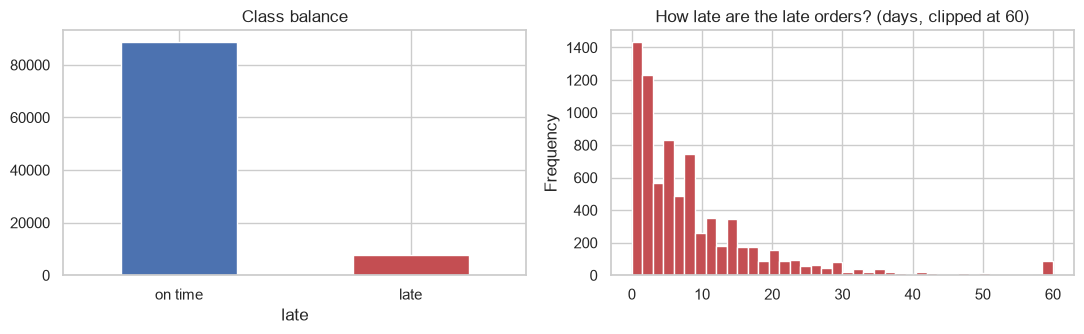

In [13]:
delivered = (orders[orders["order_status"] == "delivered"]
             .dropna(subset=["order_delivered_customer_date", "order_estimated_delivery_date"])
             .copy())
delivered["late"] = (delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]).astype(int)
delivered["delay_days"] = (delivered["order_delivered_customer_date"]
                           - delivered["order_estimated_delivery_date"]).dt.total_seconds() / 86400

# Sanity checks on the raw timestamps
bad_time = (delivered["order_delivered_customer_date"] < delivered["order_purchase_timestamp"]).sum()
print(f"Orders in raw table: {len(orders):,} | delivered with a date: {len(delivered):,} | delivered before purchase (bad rows): {bad_time}")
print(f"Late rate: {delivered['late'].mean():.2%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
delivered["late"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_xticklabels(["on time", "late"], rotation=0); ax[0].set_title("Class balance")
delivered.loc[delivered["late"] == 1, "delay_days"].clip(upper=60).plot.hist(bins=40, ax=ax[1], color="#C44E52")
ax[1].set_title("How late are the late orders? (days, clipped at 60)")
plt.tight_layout(); plt.show()

**Join plan**

```
orders ─┬─ customers (zip prefix, state)
        ├─ order_items ─┬─ products ─ category_translation
        │               └─ sellers (zip prefix, state)
        ├─ order_payments
        └─ geolocation (median lat/lng per zip prefix → distance)
```

An order may contain several items, possibly from several sellers. We create **one row per order**:
- numeric aggregates over items (count, price, freight, weight, volume),
- the **main item** (highest price) decides the order's `main_category` and the `seller_id` whose location is used.

In [14]:
# ── 1) Geolocation: many noisy GPS rows per zip prefix → one robust centroid per prefix
geo = geolocation[geolocation["geolocation_lat"].between(-35, 6) & geolocation["geolocation_lng"].between(-75, -33)]  # keep points inside Brazil
geo = (geo.groupby("geolocation_zip_code_prefix")
          .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"),
               state=("geolocation_state", lambda s: s.mode().iat[0]))
          .reset_index().rename(columns={"geolocation_zip_code_prefix": "zip_prefix"}))
print("Zip prefixes with coordinates:", len(geo))

# ── 2) Items + products + English category names
it = (items.merge(products, on="product_id", how="left")
           .merge(category_tr, on="product_category_name", how="left"))
it["category"] = (it["product_category_name_english"].fillna(it["product_category_name"]).fillna("unknown"))
it["volume_cm3"] = it["product_length_cm"] * it["product_height_cm"] * it["product_width_cm"]

order_agg = it.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    n_categories=("category", "nunique"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
    total_volume_cm3=("volume_cm3", "sum"),
)
# sum() of all-NaN groups gives 0; weight/volume of 0 is not real → treat as missing
for c in ["total_weight_g", "total_volume_cm3"]:
    order_agg.loc[order_agg[c] <= 0, c] = np.nan
order_agg = order_agg.reset_index()

main_item = (it.sort_values(["order_id", "price"], ascending=[True, False])
               .drop_duplicates("order_id")[["order_id", "seller_id", "category"]]
               .rename(columns={"category": "main_category"}))

# ── 3) Payment chosen at checkout (largest payment of the order)
pay = (payments.sort_values(["order_id", "payment_value"], ascending=[True, False])
               .drop_duplicates("order_id")[["order_id", "payment_type", "payment_installments"]])

# ── 4) Locations
geo_c = geo.rename(columns={"zip_prefix": "customer_zip_code_prefix", "lat": "cust_lat", "lng": "cust_lng"})[
    ["customer_zip_code_prefix", "cust_lat", "cust_lng"]]
geo_s = geo.rename(columns={"zip_prefix": "seller_zip_code_prefix", "lat": "sell_lat", "lng": "sell_lng"})[
    ["seller_zip_code_prefix", "sell_lat", "sell_lng"]]

# ── 5) Join everything on the order level
df = (delivered
      .merge(customers[["customer_id", "customer_zip_code_prefix", "customer_state"]], on="customer_id", how="left")
      .merge(order_agg, on="order_id", how="inner")
      .merge(main_item, on="order_id", how="left")
      .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]], on="seller_id", how="left")
      .merge(pay, on="order_id", how="left")
      .merge(geo_c, on="customer_zip_code_prefix", how="left")
      .merge(geo_s, on="seller_zip_code_prefix", how="left"))

assert df["order_id"].is_unique, "Join created duplicate orders!"
print(f"Joined table: {df.shape[0]:,} orders x {df.shape[1]} columns")
print("Orders without a geo centroid → distance will be NaN: "
      f"customer {df['cust_lat'].isna().mean():.2%}, seller {df['sell_lat'].isna().mean():.2%}")

Zip prefixes with coordinates: 19010
Joined table: 96,470 orders x 29 columns
Orders without a geo centroid → distance will be NaN: customer 0.27%, seller 0.22%


### Feature engineering (purchase-time information only)

All of these are **deterministic row-wise transformations**. They fit nothing from the data, so they are safe to compute before the split.
- `distance_km`: haversine distance between seller and customer zip-prefix centroids.
- `estimated_days`: promised delivery time = estimated date − purchase date (visible to the customer at checkout, so legitimate).
- `same_state`, `route` (e.g. `SP>BA`), `freight_ratio`, and purchase month / weekday / hour.

We also drop the sparse 2016 orders (only a few hundred orders, in a different regime).

In [15]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [np.radians(np.asarray(v, dtype=float)) for v in (lat1, lon1, lat2, lon2)]
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

df = df[df["order_purchase_timestamp"] >= "2017-01-01"].copy()

df["distance_km"]    = haversine_km(df["sell_lat"], df["sell_lng"], df["cust_lat"], df["cust_lng"])
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
df["same_state"]     = (df["customer_state"] == df["seller_state"]).astype(int)
df["route"]          = df["seller_state"].astype(str) + ">" + df["customer_state"].astype(str)
df["freight_ratio"]  = df["total_freight"] / df["total_price"].where(df["total_price"] > 0)
df["purch_month"]    = df["order_purchase_timestamp"].dt.month
df["purch_dow"]      = df["order_purchase_timestamp"].dt.dayofweek
df["purch_hour"]     = df["order_purchase_timestamp"].dt.hour
df["purch_ym"]       = df["order_purchase_timestamp"].dt.to_period("M").astype(str)   # for EDA only
df["payment_type"]         = df["payment_type"].fillna("unknown")
df["payment_installments"] = df["payment_installments"].fillna(1)

# Feature groups used by the pipeline
LOG_COLS  = ["total_price", "total_freight", "freight_ratio", "total_weight_g", "total_volume_cm3", "distance_km"]  # right-skewed → log1p
NUM_COLS  = ["estimated_days", "n_items", "n_sellers", "n_categories", "payment_installments", "same_state", "purch_hour"]
OH_COLS   = ["main_category", "customer_state", "seller_state", "payment_type", "purch_month", "purch_dow"]         # low cardinality → one-hot
TE_COLS   = ["seller_id", "route"]                                                                                  # high cardinality → target encoding (in-pipeline)
FEATURES  = LOG_COLS + NUM_COLS + OH_COLS + TE_COLS

for c in OH_COLS + TE_COLS:          # treat these as categories (e.g. month 5 is a label, not a quantity)
    df[c] = df[c].astype(str)

# Time-order everything: needed for the time-based split and for TimeSeriesSplit in CV
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)
print(f"Final modelling table: {df.shape[0]:,} orders | late rate {df['late'].mean():.2%}")
print(f"Purchase dates: {df['order_purchase_timestamp'].min().date()} → {df['order_purchase_timestamp'].max().date()}")
df[FEATURES + ["late"]].head()

Final modelling table: 96,203 orders | late rate 8.13%
Purchase dates: 2017-01-05 → 2018-08-29


,total_price,total_freight,freight_ratio,total_weight_g,total_volume_cm3,distance_km,estimated_days,n_items,n_sellers,n_categories,payment_installments,same_state,purch_hour,main_category,customer_state,seller_state,payment_type,purch_month,purch_dow,seller_id,route,late
0,10.9000,8.7200,0.8000,200.0000,352.0000,10.4316,26.5027,1,1,1,1.0000,1,11,fashion_bags_accessories,PR,PR,credit_card,1,3,48efc9d94a9834137efd9ea76b065a38,PR>PR,0
1,10.9000,8.7200,0.8000,200.0000,352.0000,10.4316,38.4991,1,1,1,1.0000,1,12,auto,PR,PR,boleto,1,3,48efc9d94a9834137efd9ea76b065a38,PR>PR,0
2,2.9000,8.7200,3.0069,200.0000,352.0000,11.5108,38.4954,1,1,1,1.0000,1,12,pet_shop,PR,PR,boleto,1,3,48efc9d94a9834137efd9ea76b065a38,PR>PR,0
3,7.9000,8.7200,1.1038,200.0000,352.0000,11.5108,38.4937,1,1,1,1.0000,1,12,pet_shop,PR,PR,boleto,1,3,48efc9d94a9834137efd9ea76b065a38,PR>PR,0
4,9.9000,8.7200,0.8808,200.0000,352.0000,11.5108,38.4921,1,1,1,1.0000,1,12,pet_shop,PR,PR,boleto,1,3,48efc9d94a9834137efd9ea76b065a38,PR>PR,0


## 4 · Train / test split (before anything is fitted)

A **time-based split** (train on earlier orders, test on the most recent 20%) mimics real deployment: a model trained on the past predicts the future. It is stricter than a random split, because delivery performance drifts (holiday peaks, carrier problems). Set `TIME_SPLIT = False` in the config for a stratified random split. If you do, say so in your limitations.

The test set is touched **once**, in section 10. All EDA, tuning, and threshold selection use the training portion only.

In [16]:
X, y = df[FEATURES], df["late"]

if TIME_SPLIT:
    cut = int(len(df) * (1 - TEST_FRAC))
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=CV_SPLITS)
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_FRAC, stratify=y, random_state=RANDOM_STATE)
    X_train, X_test, y_train, y_test = X_train.sort_index(), X_test.sort_index(), y_train.sort_index(), y_test.sort_index()
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, idx, yy in [("train", X_train.index, y_train), ("test", X_test.index, y_test)]:
    d = df.loc[idx, "order_purchase_timestamp"]
    print(f"{name:5s}: {len(idx):6,} orders | {d.min().date()} → {d.max().date()} | late rate {yy.mean():.2%}")
print("CV strategy:", type(cv).__name__)

train: 76,962 orders | 2017-01-05 → 2018-05-27 | late rate 8.84%
test : 19,241 orders | 2018-05-27 → 2018-08-29 | late rate 5.30%
CV strategy: TimeSeriesSplit


## 5 · Exploratory data analysis (training data only)

In [17]:
eda = df.loc[X_train.index].copy()

def late_rate_by(frame, col, min_n=100):
    g = frame.groupby(col, observed=True)["late"].agg(["mean", "count"])
    return g[g["count"] >= min_n].sort_values("mean", ascending=False)

def plot_rate(frame, col, ax, min_n=100, top=None, title=None):
    g = late_rate_by(frame, col, min_n)
    if top: g = g.head(top)
    sns.barplot(x=g["mean"] * 100, y=g.index.astype(str), ax=ax, color="#4C72B0", orient="h")
    ax.axvline(frame["late"].mean() * 100, color="red", ls="--", lw=1)
    ax.set_xlabel("late rate (%)  [red line = overall]"); ax.set_ylabel(""); ax.set_title(title or f"Late rate by {col}")

### 5.1 Univariate analysis

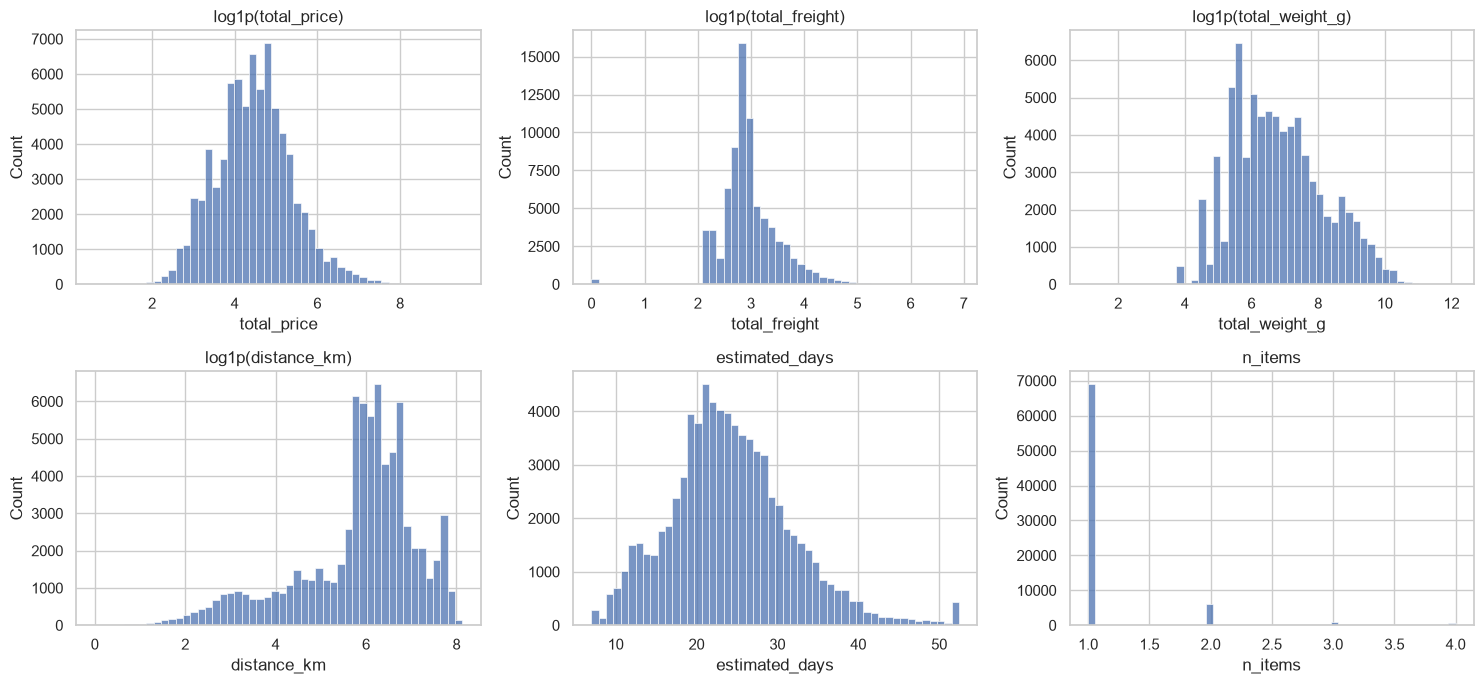

,count,mean,std,min,1%,50%,99%,max
total_price,"76,962.0000",136.5860,206.0671,0.8500,11.9900,86.9000,990.0000,"13,440.0000"
total_freight,"76,962.0000",22.2725,20.3288,0.0000,7.3900,16.7900,100.9068,"1,002.2900"
freight_ratio,"76,962.0000",0.3051,0.3133,0.0000,0.0241,0.2223,1.4416,21.4471
total_weight_g,"76,946.0000","2,463.1130","4,913.5452",2.0000,100.0000,800.0000,"22,650.0000","184,400.0000"
total_volume_cm3,"76,946.0000","17,945.6908","31,162.7209",288.0000,352.0000,"7,632.0000","140,000.0000","1,476,000.0000"
distance_km,"76,564.0000",607.9957,591.9248,0.0000,5.9710,442.7352,"2,483.9369","3,387.3144"
estimated_days,"76,962.0000",24.2306,7.8563,7.0028,9.3950,23.4822,47.3117,155.1355
n_items,"76,962.0000",1.1439,0.5449,1.0000,1.0000,1.0000,3.0000,21.0000
n_sellers,"76,962.0000",1.0129,0.1185,1.0000,1.0000,1.0000,2.0000,5.0000
n_categories,"76,962.0000",1.0078,0.0895,1.0000,1.0000,1.0000,1.0000,3.0000


Missing values in model features (train):


,missing %
total_weight_g,0.0200
total_volume_cm3,0.0200
distance_km,0.5200


In [18]:
num_plot = {"total_price": True, "total_freight": True, "total_weight_g": True,
            "distance_km": True, "estimated_days": False, "n_items": False}
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (c, use_log) in zip(axes.ravel(), num_plot.items()):
    vals = eda[c].dropna()
    sns.histplot(np.log1p(vals) if use_log else vals.clip(upper=vals.quantile(0.995)), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(("log1p(" + c + ")") if use_log else c)
plt.tight_layout(); plt.show()

display(eda[LOG_COLS + NUM_COLS].describe(percentiles=[.01, .5, .99]).T)
print("Missing values in model features (train):")
miss = eda[FEATURES].isna().mean().mul(100).round(2)
display(miss[miss > 0].to_frame("missing %"))

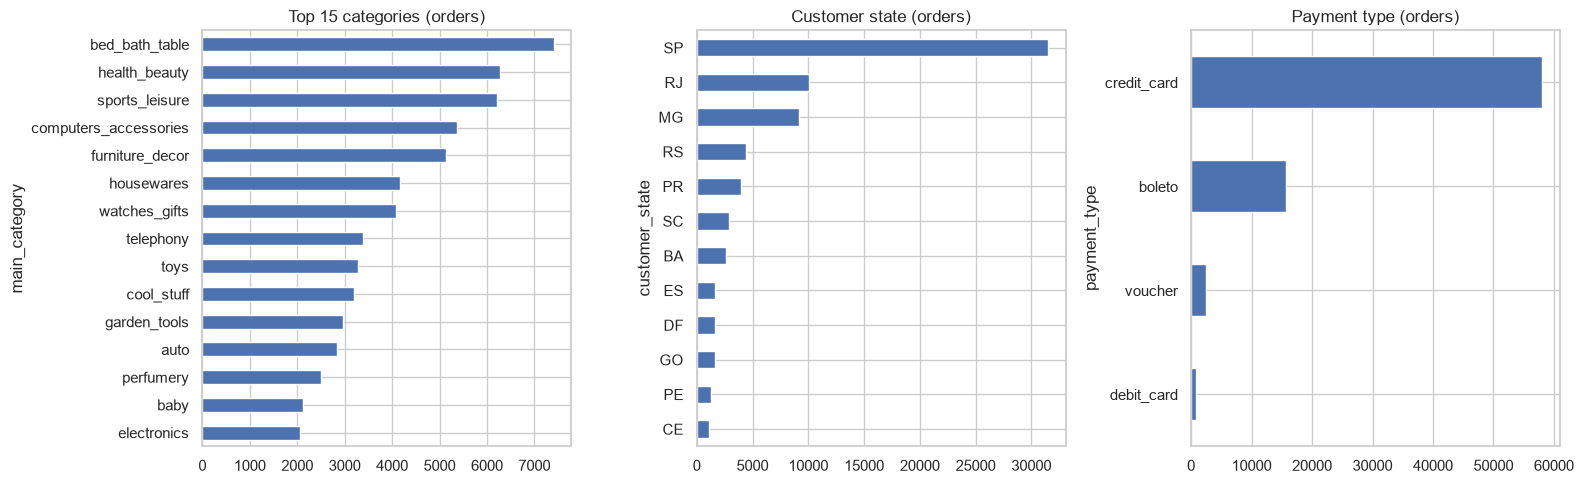

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
eda["main_category"].value_counts().head(15).sort_values().plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Top 15 categories (orders)")
eda["customer_state"].value_counts().head(12).sort_values().plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Customer state (orders)")
eda["payment_type"].value_counts().sort_values().plot.barh(ax=axes[2], color="#4C72B0"); axes[2].set_title("Payment type (orders)")
plt.tight_layout(); plt.show()

**Outliers:** price, freight, weight and distance are strongly right-skewed (long tails). We keep the extreme rows, since a 40 kg item or a 3,000 km trip is real, and handle skew with a `log1p` transform for linear models. Tree models are insensitive to it.

### 5.2 Bivariate analysis (feature vs. target)

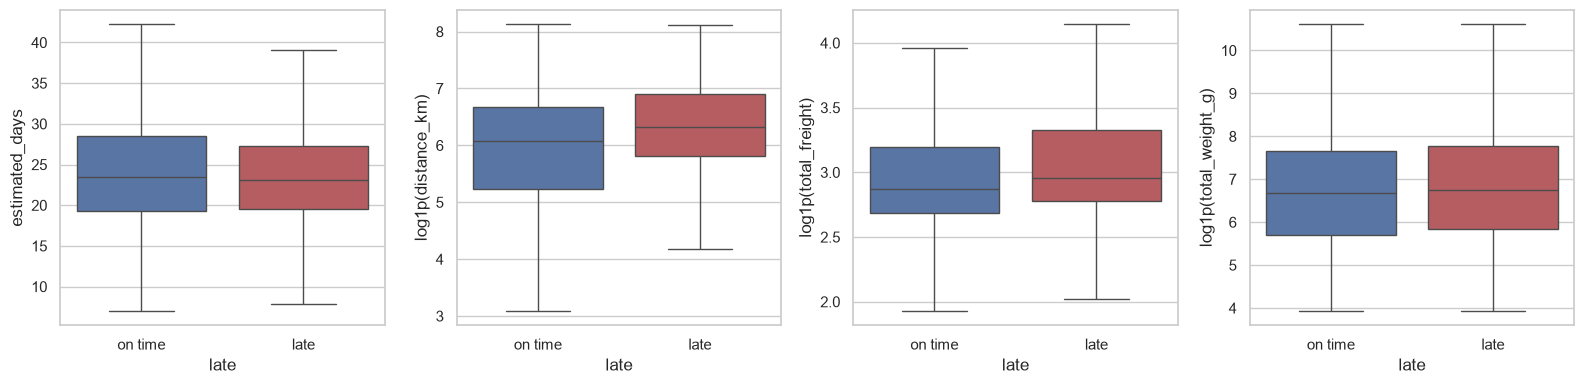

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ["estimated_days", "distance_km", "total_freight", "total_weight_g"]):
    sns.boxplot(data=eda, x="late", y=np.log1p(eda[c]) if c != "estimated_days" else eda[c],
                ax=ax, showfliers=False, palette=["#4C72B0", "#C44E52"], hue="late", legend=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["on time", "late"]); ax.set_ylabel(c if c == "estimated_days" else f"log1p({c})")
plt.tight_layout(); plt.show()

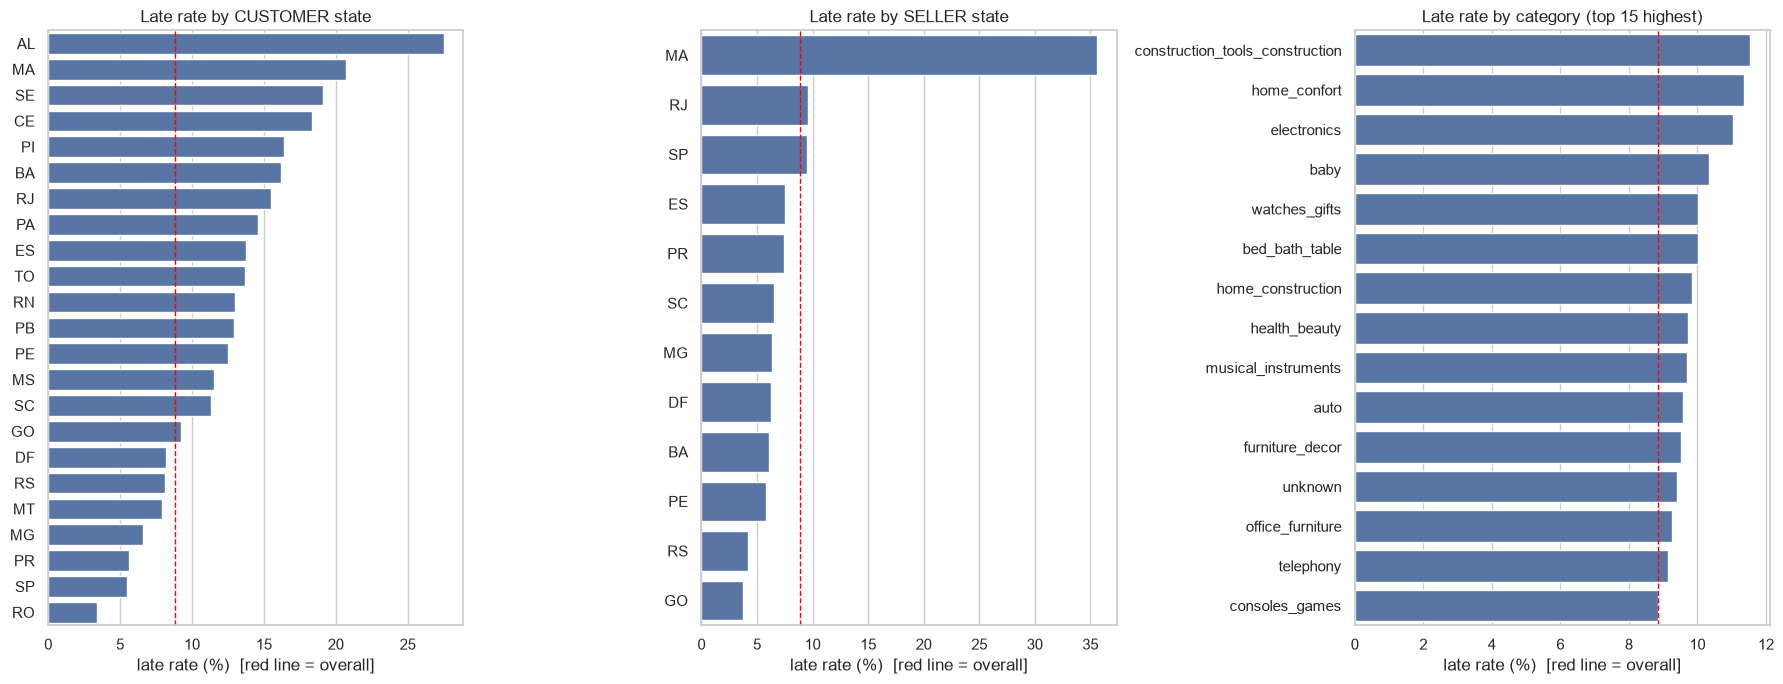

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
plot_rate(eda, "customer_state", axes[0], min_n=150, title="Late rate by CUSTOMER state")
plot_rate(eda, "seller_state",   axes[1], min_n=150, title="Late rate by SELLER state")
plot_rate(eda, "main_category",  axes[2], min_n=300, top=15, title="Late rate by category (top 15 highest)")
plt.tight_layout(); plt.show()

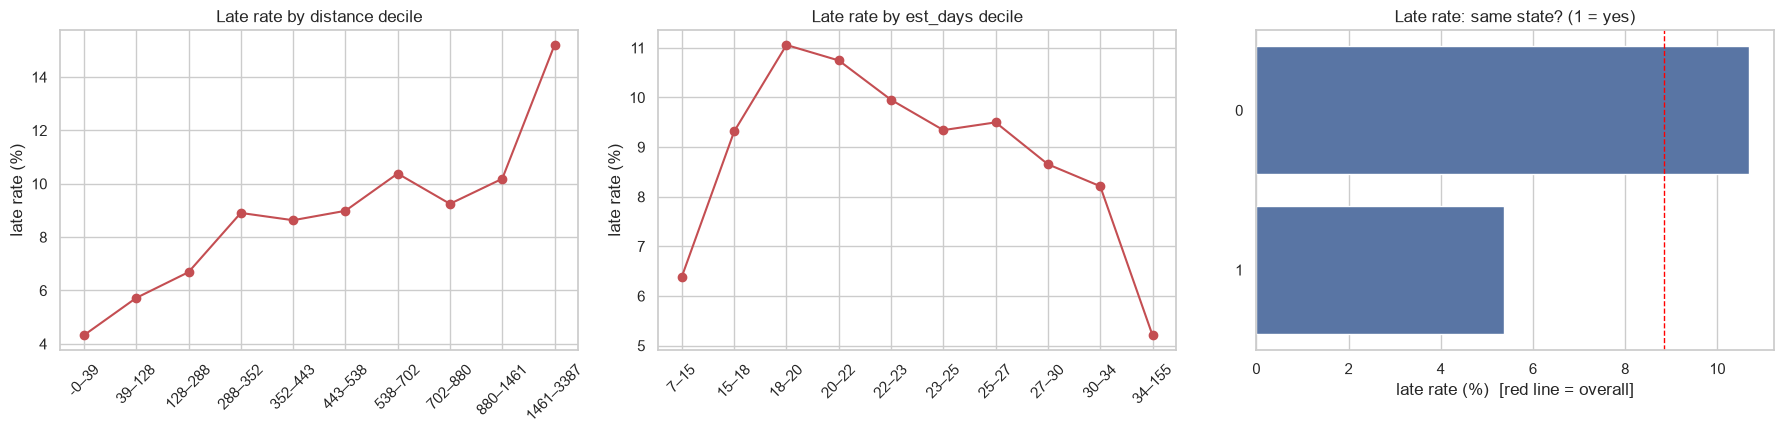

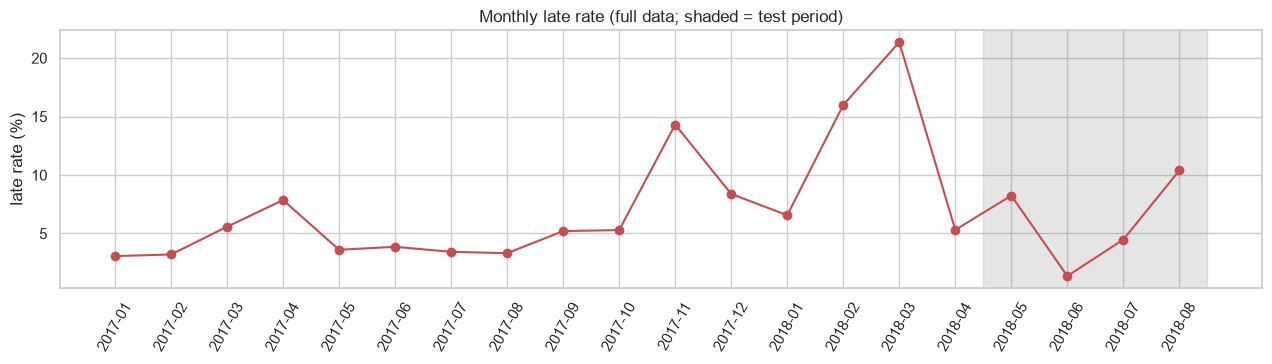

In [22]:
eda["distance_bin"] = pd.qcut(eda["distance_km"], 10, duplicates="drop")
eda["est_days_bin"] = pd.qcut(eda["estimated_days"], 10, duplicates="drop")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes[:2], ["distance_bin", "est_days_bin"]):
    r = eda.groupby(col, observed=True)["late"].mean() * 100
    ax.plot(range(len(r)), r.values, marker="o", color="#C44E52")
    ax.set_xticks(range(len(r))); ax.set_xticklabels([f"{i.left:.0f}–{i.right:.0f}" for i in r.index], rotation=45)
    ax.set_title(f"Late rate by {col.replace('_bin','')} decile"); ax.set_ylabel("late rate (%)")
plot_rate(eda, "same_state", axes[2], min_n=50, title="Late rate: same state? (1 = yes)")
plt.tight_layout(); plt.show()

# Drift check on the FULL data (descriptive only; shows why the time split matters)
monthly = df.groupby("purch_ym")["late"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(monthly.index, monthly["mean"] * 100, marker="o", color="#C44E52")
ax.set_ylabel("late rate (%)"); ax.set_title("Monthly late rate (full data; shaded = test period)"); plt.xticks(rotation=60)
test_start = df.loc[X_test.index[0], "purch_ym"]
ax.axvspan(list(monthly.index).index(test_start) - 0.5, len(monthly) - 0.5, color="grey", alpha=0.2)
plt.tight_layout(); plt.show()

### 5.3 Multivariate analysis

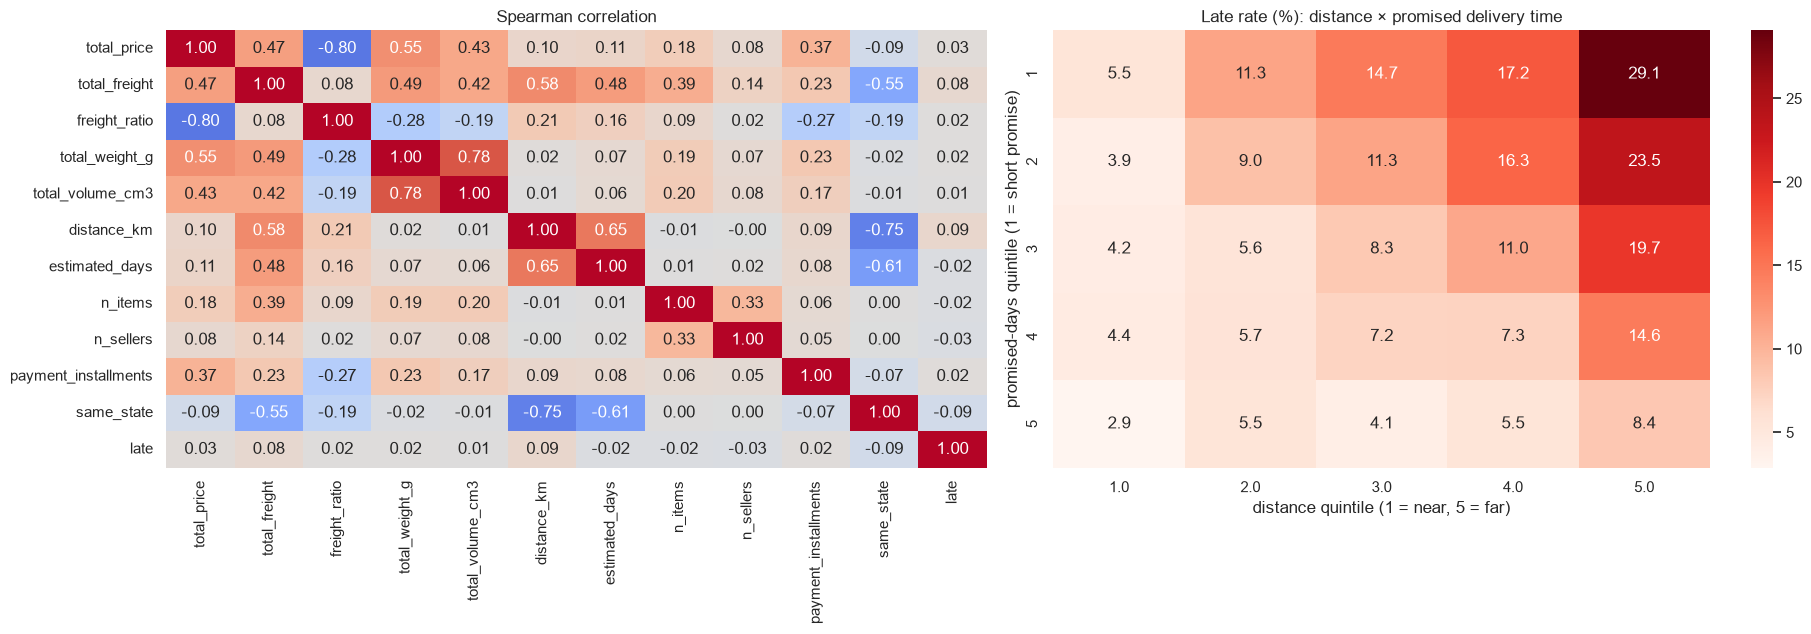

In [23]:
corr_cols = LOG_COLS + ["estimated_days", "n_items", "n_sellers", "payment_installments", "same_state", "late"]
fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))
sns.heatmap(eda[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Spearman correlation")

eda["dist_q"] = pd.qcut(eda["distance_km"], 5, labels=False, duplicates="drop") + 1
eda["est_q"]  = pd.qcut(eda["estimated_days"], 5, labels=False, duplicates="drop") + 1
pv = eda.pivot_table(index="est_q", columns="dist_q", values="late", aggfunc="mean") * 100
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Reds", ax=axes[1])
axes[1].set_xlabel("distance quintile (1 = near, 5 = far)"); axes[1].set_ylabel("promised-days quintile (1 = short promise)")
axes[1].set_title("Late rate (%): distance × promised delivery time")
plt.tight_layout(); plt.show()

### 5.4 Insights and hypotheses

After running the cells above, confirm or correct each statement with the numbers you see, and keep 3–5 of them in your presentation.

1. **Promised time vs. distance.** Orders with a *short* promise and a *long* distance should have the highest late rate (heatmap). Predicting lateness is largely about whether the promise was realistic for the route.
2. **Geography.** Late rates should be higher for customers in the North / North-East states, and for orders crossing state lines, because carrier networks there are thinner.
3. **Seasonality and drift.** The monthly late rate should spike in peak periods (e.g. Black Friday Nov-2017 and early 2018). A model trained on calm months will under-predict these, which is the case for the time-based split.
4. **Seller and lane effects.** Some sellers and seller→customer state routes should sit far above the average, so `seller_id` and `route` carry signal (target-encoded inside the pipeline to avoid leakage).
5. **Weak product signals.** Price, weight and category should be weakly related to lateness compared with distance and the promised time, so we expect modest overall predictability.

## 6 · Preprocessing pipeline

Everything that learns from data lives **inside** one scikit-learn `Pipeline`, so cross-validation refits it on each fold and no information leaks from validation or test rows.

| Feature group | Steps |
|---|---|
| Skewed numerics (`LOG_COLS`) | median imputation (+ missing indicator) → `log1p` → standard scaling |
| Other numerics (`NUM_COLS`) | median imputation → standard scaling |
| Low-cardinality categoricals | one-hot encoding (rare levels grouped, unseen levels tolerated) |
| `seller_id`, `route` | **`TargetEncoder`** with smoothing and internal cross-fitting, which gives the seller's/lane's historical late rate computed only on training rows, shrunk toward the global rate for sellers with few orders |

In [24]:
def make_preprocessor():
    log_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return ColumnTransformer([
        ("log", log_pipe, LOG_COLS),
        ("num", num_pipe, NUM_COLS),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), OH_COLS),
        ("target", TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=RANDOM_STATE), TE_COLS),
    ], sparse_threshold=0, verbose_feature_names_out=False)

def make_pipeline(clf):
    return Pipeline([("prep", make_preprocessor()), ("clf", clf)])

# Smoke test: fit the preprocessor on TRAIN only and inspect the output shape
_probe = make_preprocessor().fit(X_train, y_train)
print("Transformed training matrix:", _probe.transform(X_train.head(1000)).shape)

Transformed training matrix: (1000, 131)


## 7 · Baseline and model comparison

- **Baseline:** `DummyClassifier` (always predicts the prior). Any real model must beat its PR-AUC, which equals the late rate.
- **Three algorithms**, each handling imbalance via class weights:
  - Logistic Regression (simple, interpretable)
  - Random Forest (bagged trees)
  - HistGradientBoosting (boosted trees, fast on 100K rows)

We compare them using cross-validation on the **training set**, scoring with PR-AUC and ROC-AUC.

In [25]:
models = {
    "Baseline (Dummy)":      DummyClassifier(strategy="prior"),
    "Logistic Regression":   LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random Forest":         RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight="balanced_subsample",
                                                    n_jobs=1, random_state=RANDOM_STATE),
    "HistGradientBoosting":  HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE),
}

rows = []
for name, clf in models.items():
    res = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, n_jobs=-1,
                         scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    rows.append({"model": name, "CV PR-AUC": res["test_pr_auc"].mean(), "± PR-AUC": res["test_pr_auc"].std(),
                 "CV ROC-AUC": res["test_roc_auc"].mean(), "± ROC-AUC": res["test_roc_auc"].std()})
cv_default = pd.DataFrame(rows).set_index("model")
print(f"Late rate in train (= PR-AUC of a useless model): {y_train.mean():.3f}")
cv_default

Late rate in train (= PR-AUC of a useless model): 0.088


,CV PR-AUC,± PR-AUC,CV ROC-AUC,± ROC-AUC
model,,,,
Baseline (Dummy),0.0991,0.0446,0.5000,0.0000
Logistic Regression,0.1840,0.0860,0.6724,0.0377
Random Forest,0.1846,0.0836,0.6557,0.0227
HistGradientBoosting,0.1801,0.0783,0.6535,0.0161


## 8 · Hyperparameter tuning

`RandomizedSearchCV` on the **training set only**, with the same CV splitter and `average_precision` as the objective. Random search covers wide ranges more cheaply than a full grid.

In [26]:
search_spaces = {
    "Logistic Regression": {"clf__C": loguniform(1e-3, 10)},
    "Random Forest": {
        "clf__n_estimators": [200, 300],
        "clf__max_depth": [8, 12, 16, None],
        "clf__min_samples_leaf": randint(5, 60),
        "clf__max_features": ["sqrt", 0.3],
    },
    "HistGradientBoosting": {
        "clf__learning_rate": loguniform(0.02, 0.2),
        "clf__max_iter": randint(150, 500),
        "clf__max_leaf_nodes": randint(15, 63),
        "clf__min_samples_leaf": randint(20, 200),
        "clf__l2_regularization": loguniform(1e-3, 10),
    },
}

searches = {}
for name, space in search_spaces.items():
    rs = RandomizedSearchCV(make_pipeline(clone(models[name])), space, n_iter=N_ITER[name],
                            scoring="average_precision", cv=cv, n_jobs=-1,
                            random_state=RANDOM_STATE, refit=True)
    rs.fit(X_train, y_train)
    searches[name] = rs
    print(f"{name:22s} best CV PR-AUC = {rs.best_score_:.4f}")

tuning_table = pd.DataFrame({
    "default CV PR-AUC": cv_default["CV PR-AUC"].drop("Baseline (Dummy)"),
    "tuned CV PR-AUC": {n: s.best_score_ for n, s in searches.items()},
})
display(tuning_table)
for n, s in searches.items():
    print(n, "→", {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})

# Model selection uses CV results ONLY (never the test set)
best_name = max(searches, key=lambda n: searches[n].best_score_)
print(f"\nSelected model (best CV PR-AUC): {best_name}")

Logistic Regression    best CV PR-AUC = 0.1898
Random Forest          best CV PR-AUC = 0.1817
HistGradientBoosting   best CV PR-AUC = 0.1841


,default CV PR-AUC,tuned CV PR-AUC
Logistic Regression,0.1840,0.1898
Random Forest,0.1846,0.1817
HistGradientBoosting,0.1801,0.1841


Logistic Regression → {'C': np.float64(0.0315)}
Random Forest → {'max_depth': 16, 'max_features': 0.3, 'min_samples_leaf': 33, 'n_estimators': 200}
HistGradientBoosting → {'l2_regularization': np.float64(0.0216), 'learning_rate': np.float64(0.0278), 'max_iter': 280, 'max_leaf_nodes': 36, 'min_samples_leaf': 72}

Selected model (best CV PR-AUC): Logistic Regression


## 9 · Choosing the decision threshold from business cost

A probability must be turned into a "warn / don't warn" decision. With `COST_FN = 5` and `COST_FP = 1` we pick the threshold that minimises

`cost = COST_FN × (missed late orders) + COST_FP × (false alarms)`

on a **validation slice carved from the end of the training set** (the model is fitted on the earlier 85% of the training data). The test set plays no part.

Logistic Regression    chosen threshold = 0.71
Random Forest          chosen threshold = 0.72
HistGradientBoosting   chosen threshold = 0.71


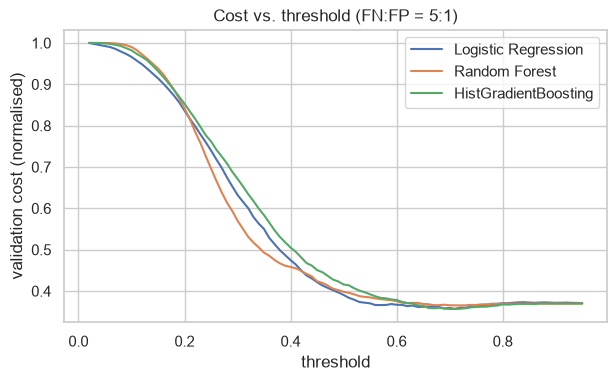

In [27]:
def pick_threshold(pipe, X_tr, y_tr, c_fn=COST_FN, c_fp=COST_FP, val_frac=0.15):
    n = len(X_tr); cut = int(n * (1 - val_frac))                       # X_train is time-ordered
    m = clone(pipe).fit(X_tr.iloc[:cut], y_tr.iloc[:cut])
    p = m.predict_proba(X_tr.iloc[cut:])[:, 1]; yv = y_tr.iloc[cut:].to_numpy()
    grid = np.linspace(0.02, 0.95, 94)
    costs = np.array([c_fn * ((p < t) & (yv == 1)).sum() + c_fp * ((p >= t) & (yv == 0)).sum() for t in grid])
    return {"threshold": float(grid[costs.argmin()]), "grid": grid, "costs": costs}

thr_info = {n: pick_threshold(s.best_estimator_, X_train, y_train) for n, s in searches.items()}
for n, t in thr_info.items():
    print(f"{n:22s} chosen threshold = {t['threshold']:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for n, t in thr_info.items():
    ax.plot(t["grid"], t["costs"] / t["costs"].max(), label=n)
ax.set_xlabel("threshold"); ax.set_ylabel("validation cost (normalised)")
ax.set_title(f"Cost vs. threshold (FN:FP = {COST_FN:g}:{COST_FP:g})"); ax.legend(); plt.show()

## 10 · Final evaluation on the untouched test set

The tuned pipelines were fitted on the full training set. This is the **first and only** time the test set is used.

In [28]:
def metrics_at(y_true, proba, thr, c_fn=COST_FN, c_fp=COST_FP):
    pred = (proba >= thr).astype(int)
    fn = int(((pred == 0) & (y_true == 1)).sum()); fp = int(((pred == 1) & (y_true == 0)).sum())
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "threshold": thr, "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred, zero_division=0),
            "flagged %": pred.mean() * 100, "cost": c_fn * fn + c_fp * fp}

y_test_np = y_test.to_numpy()
test_proba = {n: s.best_estimator_.predict_proba(X_test)[:, 1] for n, s in searches.items()}

base = DummyClassifier(strategy="prior").fit(X_train, y_train)
base_row = {"ROC-AUC": 0.5, "PR-AUC": y_test.mean(), "threshold": np.nan, "precision": 0.0, "recall": 0.0, "F1": 0.0,
            "flagged %": 0.0, "cost": COST_FN * y_test.sum()}

results = pd.DataFrame({"Baseline (Dummy)": base_row, **{n: metrics_at(y_test_np, p, thr_info[n]["threshold"])
                                                          for n, p in test_proba.items()}}).T
results["selected"] = ["" ] + ["◄ best by CV" if n == best_name else "" for n in test_proba]
print(f"Test set: {len(y_test):,} orders, late rate {y_test.mean():.2%}")
results

Test set: 19,241 orders, late rate 5.30%


,ROC-AUC,PR-AUC,threshold,precision,recall,F1,flagged %,cost,selected
Baseline (Dummy),0.5000,0.0530,NaN,0.0000,0.0000,0.0000,0.0000,"5,100.0000",
Logistic Regression,0.6920,0.1010,0.7100,0.1818,0.0765,0.1077,2.2296,"5,061.0000",◄ best by CV
Random Forest,0.6770,0.0941,0.7200,0.0000,0.0000,0.0000,0.0000,"5,100.0000",
HistGradientBoosting,0.6662,0.0899,0.7100,0.1662,0.0549,0.0825,1.7515,"5,101.0000",


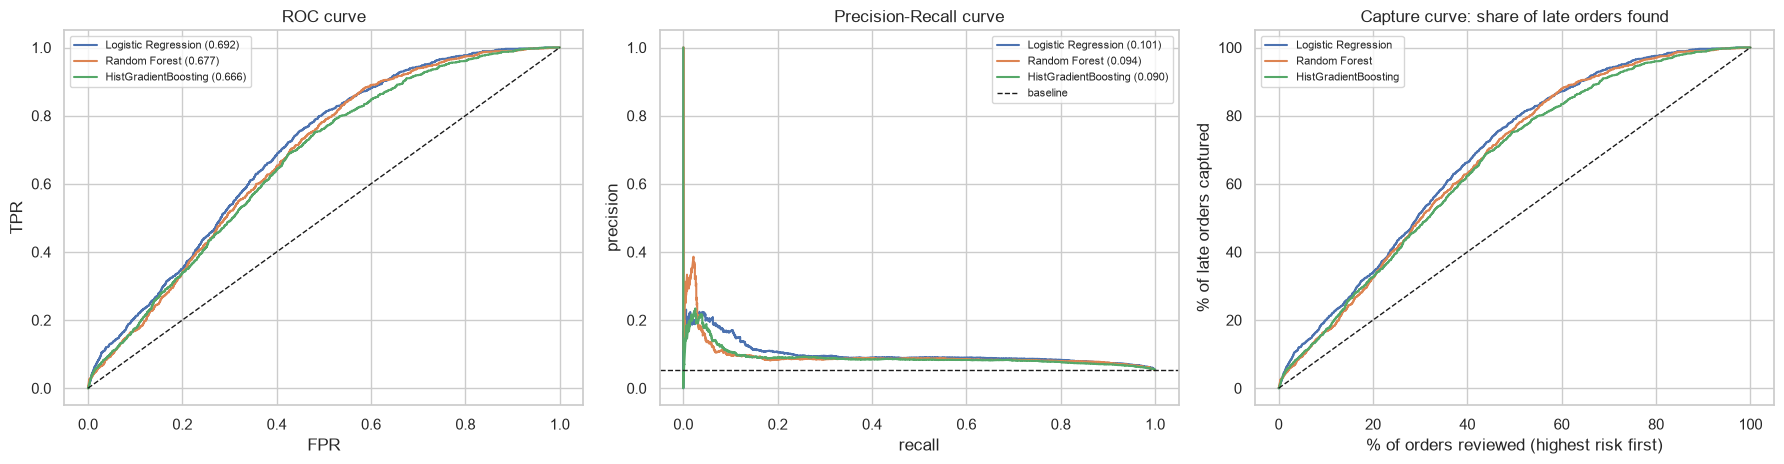

Reviewing the riskiest  5% of orders captures 12.7% of all late orders (Logistic Regression)
Reviewing the riskiest 10% of orders captures 19.9% of all late orders (Logistic Regression)
Reviewing the riskiest 20% of orders captures 34.0% of all late orders (Logistic Regression)


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test_np, p); axes[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test_np, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test_np, p); axes[1].plot(rc, pr, label=f"{n} ({average_precision_score(y_test_np, p):.3f})")
    order = np.argsort(-p); cum = np.cumsum(y_test_np[order]) / y_test_np.sum()
    axes[2].plot(np.arange(1, len(p) + 1) / len(p) * 100, cum * 100, label=n)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="baseline"); axes[1].set_title("Precision-Recall curve")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[2].plot([0, 100], [0, 100], "k--", lw=1); axes[2].set_title("Capture curve: share of late orders found")
axes[2].set_xlabel("% of orders reviewed (highest risk first)"); axes[2].set_ylabel("% of late orders captured")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

p = test_proba[best_name]; order = np.argsort(-p); cum = np.cumsum(y_test_np[order]) / y_test_np.sum()
for k in (5, 10, 20):
    print(f"Reviewing the riskiest {k:>2}% of orders captures {cum[int(len(p) * k / 100) - 1]:.1%} of all late orders ({best_name})")

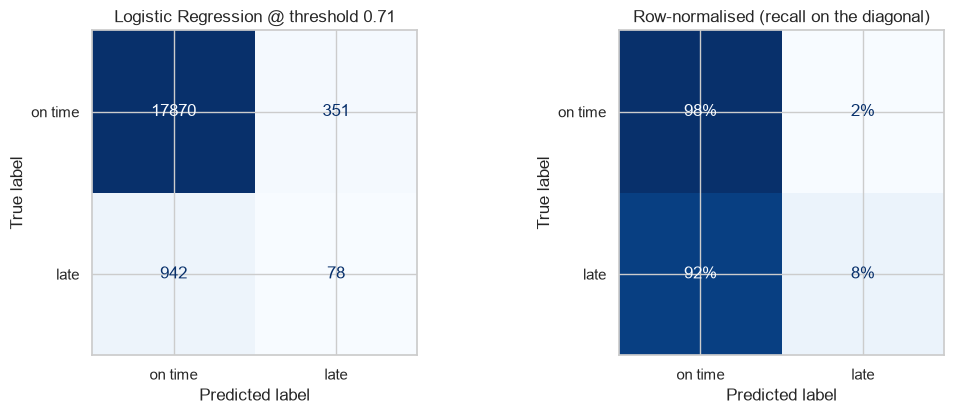

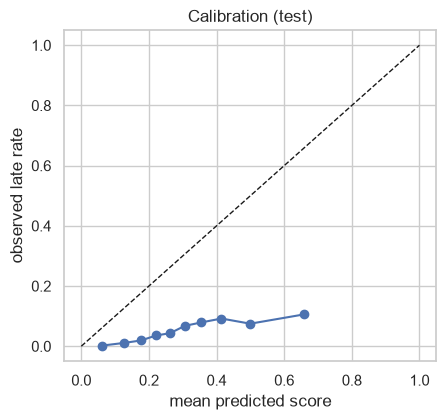

Brier score: 0.1339


In [30]:
best_thr = thr_info[best_name]["threshold"]
best_pred = (test_proba[best_name] >= best_thr).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay.from_predictions(y_test_np, best_pred, display_labels=["on time", "late"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"{best_name} @ threshold {best_thr:.2f}")
ConfusionMatrixDisplay.from_predictions(y_test_np, best_pred, display_labels=["on time", "late"], normalize="true",
                                        values_format=".0%", cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Row-normalised (recall on the diagonal)")
plt.tight_layout(); plt.show()

# Are the scores real probabilities? (class_weight inflates them)
frac_pos, mean_pred = calibration_curve(y_test_np, test_proba[best_name], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.8, 4.3))
ax.plot(mean_pred, frac_pos, marker="o"); ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("mean predicted score"); ax.set_ylabel("observed late rate"); ax.set_title("Calibration (test)")
plt.show()
print(f"Brier score: {brier_score_loss(y_test_np, test_proba[best_name]):.4f}")

**Reading the calibration curve.** Because we trained with class weights, the output is a **risk score**, not a literal probability (scores sit above the observed late rate). In the app, present it as a *risk band* (Low / Medium / High) or a relative score. Do not say "this order has a 62% chance of being late" unless you calibrate the model, for example with `CalibratedClassifierCV`.

### Error analysis

Where does the model miss late orders (false negatives) and raise false alarms (false positives)?

In [31]:
test_df = df.loc[X_test.index].copy()
test_df["score"] = test_proba[best_name]; test_df["pred"] = best_pred
late_only, ontime_only = test_df[test_df["late"] == 1], test_df[test_df["late"] == 0]

def breakdown(col, min_n=20, top=12):
    r = late_only.groupby(col)["pred"].agg(recall="mean", late_orders="count")
    f = ontime_only.groupby(col)["pred"].agg(false_alarm_rate="mean", ontime_orders="count")
    out = r.join(f, how="outer")
    return out[out["late_orders"] >= min_n].sort_values("recall").head(top)

for col in ["customer_state", "main_category", "purch_ym"]:
    print(f"\nWorst recall by {col} (late orders only)")
    display(breakdown(col))

print("\nMissed (pred=0) vs caught (pred=1) late orders; median feature values:")
display(late_only.groupby("pred")[["estimated_days", "distance_km", "total_price", "total_freight"]].median()
        .rename(index={0: "missed (FN)", 1: "caught (TP)"}))


Worst recall by customer_state (late orders only)


,recall,late_orders,false_alarm_rate,ontime_orders
customer_state,,,,
MG,0.0000,34.0000,0.0033,2094
PR,0.0000,24.0000,0.0053,950
SP,0.0181,664.0000,0.0016,8234
RS,0.1667,24.0000,0.0176,911
BA,0.1818,33.0000,0.0580,603
RJ,0.3021,96.0000,0.0631,2107



Worst recall by main_category (late orders only)


,recall,late_orders,false_alarm_rate,ontime_orders
main_category,,,,
telephony,0.0000,38.0000,0.0142,633.0000
construction_tools_construction,0.0000,22.0000,0.0192,312.0000
food,0.0000,21.0000,0.0184,163.0000
auto,0.0179,56.0000,0.0191,891.0000
housewares,0.0235,85.0000,0.0154,"1,424.0000"
toys,0.0345,29.0000,0.0172,464.0000
watches_gifts,0.0345,58.0000,0.0106,"1,324.0000"
computers_accessories,0.0385,52.0000,0.0083,"1,088.0000"
cool_stuff,0.0417,24.0000,0.0064,312.0000



Worst recall by purch_ym (late orders only)


,recall,late_orders,false_alarm_rate,ontime_orders
purch_ym,,,,
2018-06,0.0241,83,0.0042,6013
2018-08,0.0530,660,0.0362,5691
2018-07,0.1486,276,0.0202,5880



Missed (pred=0) vs caught (pred=1) late orders; median feature values:


,estimated_days,distance_km,total_price,total_freight
pred,,,,
missed (FN),8.0451,90.5702,79.9000,13.9750
caught (TP),16.0064,"1,171.2584",122.9900,27.7500


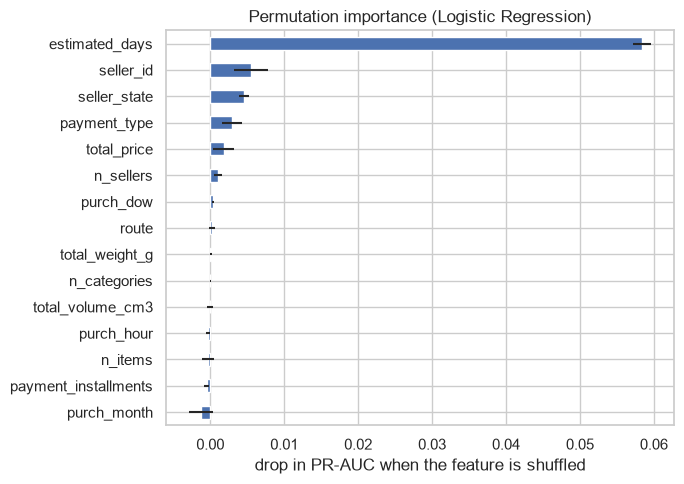

In [32]:
# Which input features does the selected model rely on? (permutation importance, scored with PR-AUC)
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_test), size=min(8000, len(X_test)), replace=False)
perm = permutation_importance(searches[best_name].best_estimator_, X_test.iloc[idx], y_test.iloc[idx],
                              scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index], color="#4C72B0")
ax.set_xlabel("drop in PR-AUC when the feature is shuffled"); ax.set_title(f"Permutation importance ({best_name})")
plt.tight_layout(); plt.show()

## 11 · Business insight and limitations

> Fill the numbers from the tables above before presenting.

**What the results mean**
- The model gives each order a **risk score at checkout**. Reviewing the riskiest **10%** of orders catches **[X]%** of all late deliveries (capture curve), against 10% for random selection.
- At the cost-optimal threshold the model flags **[Y]%** of orders, with **recall [R]%** and **precision [P]%**. Roughly **[1 in N]** flagged orders is truly late, so warnings should be low-cost, e.g. a message that sets expectations. Costly actions such as expediting should be saved for the highest band.
- The strongest drivers should be promised delivery time, distance / route, and seller history (see permutation importance), so the operational lever is **setting realistic estimates** as much as predicting.

**Recommended next steps**
1. **Pilot proactive notifications** for the High band and measure the effect on review scores (A/B test).
2. **Re-estimate delivery promises** for lanes and sellers that are consistently late (a simple, high-impact fix).
3. **Seller watch-list:** use the seller page to coach or flag sellers with high late rates and enough volume.
4. **Monitor and retrain** monthly: delivery performance drifts with seasons and carrier capacity.

**Limitations**
- Late deliveries depend on events we do not observe at purchase time (weather, strikes, carrier capacity, seller handling time), so a performance ceiling is expected and precision is modest.
- Distance uses **zip-prefix centroids**, not exact addresses, and some prefixes have no coordinates (imputed).
- Data covers 2017–2018 in Brazil. Drift is real (see the monthly chart), and the holiday peak is hard to predict.
- Seller / route encodings are learned from history: **new sellers get the global average** (cold start).
- Scores are not calibrated probabilities (class weighting), so the app shows risk bands.
- The cost ratio (5:1) is an assumption; the right threshold depends on the company's real costs.
- Orders with several sellers are represented by the highest-priced item's seller.

## 12 · Export artifacts for the Streamlit app

1. **Final pipeline:** refit the selected pipeline (same hyper-parameters) on **all** labelled data, since the test period has now served its purpose, and save with `joblib`.
2. **Metadata:** threshold, risk-band cut-offs, feature lists, dropdown options, library versions.
3. **Small lookup files** the app needs: `zip_lookup.csv` (zip prefix → lat/lng/state) and `seller_stats.csv` (late rate per seller). These are descriptive tables and are not used as model inputs.

> Seller late rate in `seller_stats.csv` is computed on all delivered orders and is only for the **display page**. The model's own seller feature is the leakage-safe target encoding inside the pipeline.

In [33]:
final_model = clone(searches[best_name].best_estimator_).fit(X, y)       # all data
joblib.dump(final_model, MODEL_DIR / "late_pipeline.joblib", compress=3)

thr = float(best_thr)
metadata = {
    "model_name": best_name,
    "threshold": thr,
    "risk_bands": {"medium_from": round(0.6 * thr, 3), "high_from": round(thr, 3)},   # Low < medium_from <= Medium < high_from <= High
    "features": FEATURES, "log_cols": LOG_COLS, "num_cols": NUM_COLS, "onehot_cols": OH_COLS, "target_enc_cols": TE_COLS,
    "test_metrics": {k: float(v) for k, v in results.loc[best_name, ["ROC-AUC", "PR-AUC", "precision", "recall", "F1"]].items()},
    "cost_ratio_fn_fp": [COST_FN, COST_FP],
    "trained_on": f"{df['order_purchase_timestamp'].min().date()} to {df['order_purchase_timestamp'].max().date()}",
    "n_orders": int(len(df)),
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "ui_options": {
        "categories": sorted(df["main_category"].unique().tolist()),
        "payment_types": sorted(df["payment_type"].unique().tolist()),
        "states": sorted(df["customer_state"].unique().tolist()),
    },
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

# Zip lookup (only prefixes that appear in orders keeps the file small)
used_zips = set(df["customer_zip_code_prefix"]) | set(df["seller_zip_code_prefix"])
zip_lookup = geo[geo["zip_prefix"].isin(used_zips)].round({"lat": 4, "lng": 4})
zip_lookup.to_csv(APP_DATA_DIR / "zip_lookup.csv", index=False)

# Seller stats for the seller page (descriptive)
seller_stats = (df.groupby("seller_id")
                  .agg(seller_state=("seller_state", "first"), seller_zip=("seller_zip_code_prefix", "first"),
                       n_orders=("late", "size"), late_rate=("late", "mean"),
                       avg_days_late_when_late=("delay_days", lambda s: s[s > 0].mean()))
                  .reset_index().sort_values("n_orders", ascending=False))
seller_stats.to_csv(APP_DATA_DIR / "seller_stats.csv", index=False)

results.drop(columns="selected").round(4).to_csv("results_table.csv")

print("Saved:", [str(p) for p in [MODEL_DIR / "late_pipeline.joblib", MODEL_DIR / "metadata.json",
                                  APP_DATA_DIR / "zip_lookup.csv", APP_DATA_DIR / "seller_stats.csv", Path("results_table.csv")]])
print(f"zip_lookup rows: {len(zip_lookup):,} | sellers: {len(seller_stats):,} "
      f"({(seller_stats['n_orders'] >= 30).sum()} with 30+ orders)")
print(f"Pin in requirements.txt:  scikit-learn=={sklearn.__version__}  pandas=={pd.__version__}  numpy=={np.__version__}  joblib=={joblib.__version__}")

Saved: ['model\\late_pipeline.joblib', 'model\\metadata.json', 'data\\zip_lookup.csv', 'data\\seller_stats.csv', 'results_table.csv']
zip_lookup rows: 14,812 | sellers: 2,935 (619 with 30+ orders)
Pin in requirements.txt:  scikit-learn==1.9.1  pandas==3.0.5  numpy==2.5.3  joblib==1.6.0


In [34]:
# Reload test: confirm the saved pipeline works on raw feature rows, exactly as the app will call it
loaded = joblib.load(MODEL_DIR / "late_pipeline.joblib")
sample = X.sample(5, random_state=RANDOM_STATE)
print(loaded.predict_proba(sample)[:, 1].round(3))

[0.089 0.271 0.371 0.084 0.762]


### Next steps
- Build `app.py` (Streamlit): order form → `loaded.predict_proba` → risk band; seller page from `seller_stats.csv`.
- Write the README (results table is in `results_table.csv`), slides, and the LinkedIn post.
- Stretch goal: predict 1–2 star reviews with `review_score` and quantify the damage caused by late delivery.